# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [2]:
import pandas as pd

flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [3]:
flights.head()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [4]:
flights.tail()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [5]:
flights.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   airline                5000 non-null   object
 1   origin_city            5000 non-null   object
 2   destination_city       5000 non-null   object
 3   distance_miles         5000 non-null   int64 
 4   arrival_delay_minutes  5000 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 195.4+ KB


**How many observations are in the DataFrame?**

Your answer: 5000


Count the missing values in every feature.


In [6]:
flights.isnull().sum()


airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` |  |  |  |
| `origin_city` |  |  |  |
| `destination_city` |  |  |  |
| `distance_miles` |  |  |  |
| `arrival_delay_minutes` |  |  |  |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [8]:
destination_counts = flights["destination_city"].value_counts()

print(destination_counts)


destination_city
Chicago, IL                       296
Atlanta, GA                       222
Dallas/Fort Worth, TX             210
Denver, CO                        209
Washington, DC                    165
                                 ... 
Gunnison, CO                        1
Allentown/Bethlehem/Easton, PA      1
Idaho Falls, ID                     1
Jamestown, ND                       1
Yuma, AZ                            1
Name: count, Length: 238, dtype: int64


Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


Matplotlib is building the font cache; this may take a moment.


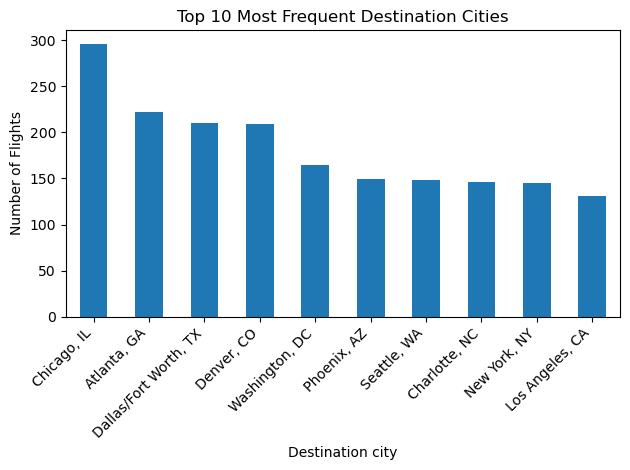

In [9]:
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind="bar")

plt.title("Top 10 Most Frequent Destination Cities")
plt.xlabel("Destination city")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Which destination city is most common in the sample?**

Your answer: Chicago, Illinois, is the most common destination city in the sample, with about 295 flights.


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


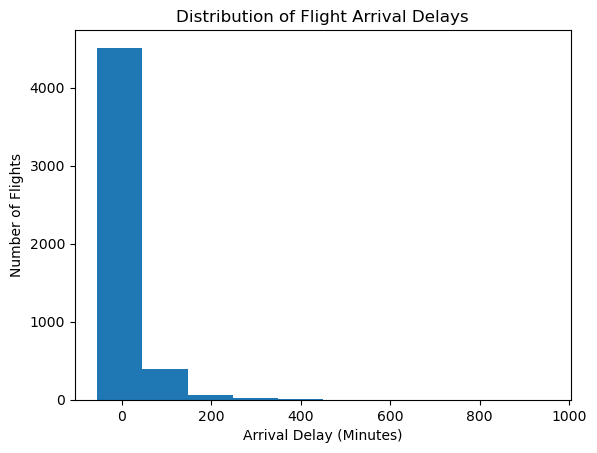

In [11]:
plt.hist(flights["arrival_delay_minutes"])

plt.title("Distribution of Flight Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.show()

**Approximately what arrival-delay value appears most common?**

Your answer: Around 0 minuetes. Most flights arrived closely to their scheduled arrival time, either slightly early or slightly late.


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer: 60 minuts to 950 minutes


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer: The distribution is strongly right-skewed because most flights had relativley small arrival delays, while a a few flights experienced extrememly long delays.


Display a numerical summary of `arrival_delay_minutes`.


In [12]:
flights["arrival_delay_minutes"].describe()

count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [13]:
flights["arrival_delay_minutes"].mode()


0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: The calculated mode was -8 minutes, which is close to my estimate of 0 minutes. This means the most frequently occuring exact arrival delay was 8 minutes early.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: The actual minimum was -55 minutes and the maximum was 953 minutes. These were very close to my estimated range of -60 to 950 minutes.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer: The mean was 6.10 minutes, which is greater than the median of -6b miniutes. 


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer: The mean is greater than the median becasue the distribution is right-skewed. A small number of flights with very long delays pull the mean higher. 


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


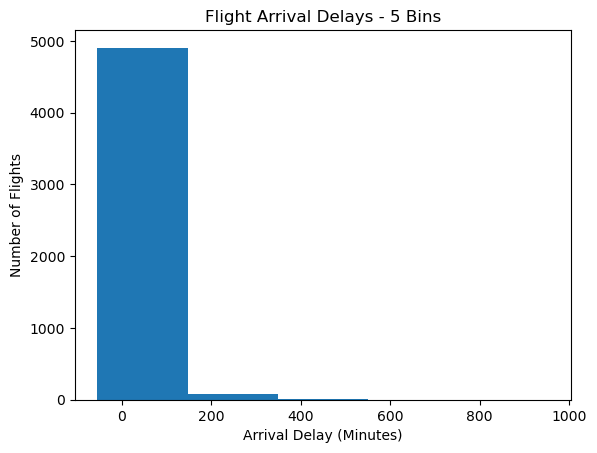

In [14]:
plt.hist(flights["arrival_delay_minutes"], bins=5)
plt.title("Flight Arrival Delays - 5 Bins")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.show()

Re-create the arrival-delay histogram using exactly 25 bins.


<function matplotlib.pyplot.show(close=None, block=None)>

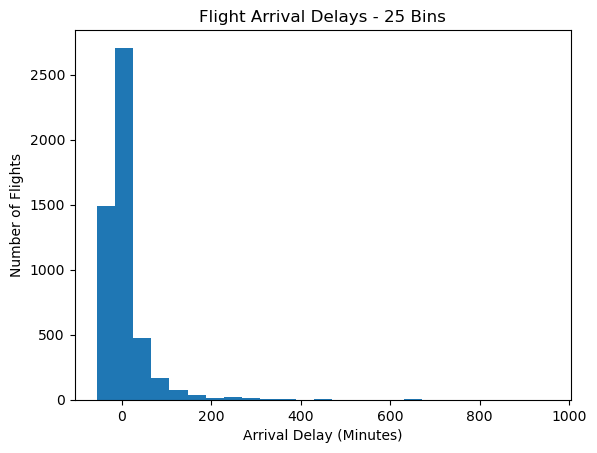

In [15]:
plt.hist(flights["arrival_delay_minutes"], bins=25)
plt.title("Flight Arrival Delays - 25 Bins")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.show

**What changed when the number of bins was reduced to 5?**

Your answer:


**What changed when the number of bins was increased to 25?**

Your answer: The bars became wider and grouped more arrival delays together. This made the graph less detailed and harder to see smaller differences in the data.


**Which bin setting communicates the distribution most clearly?**

Your answer: I think 25 bins communicates the disrtibution most clearly because it shows more detal while still making the overall right-dkewed pattern easy to understand.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


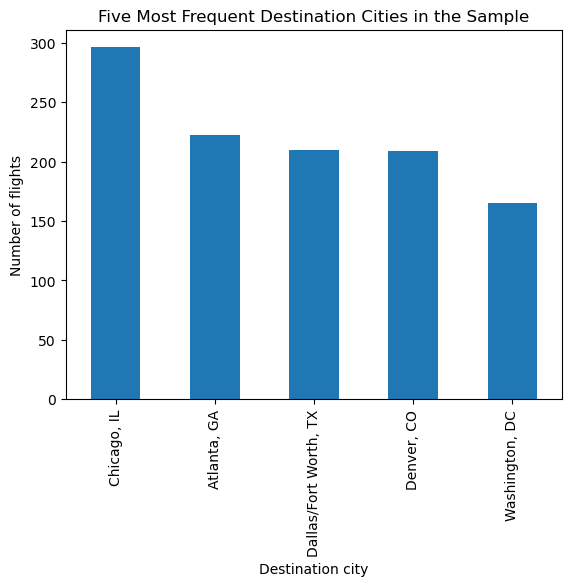

In [16]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


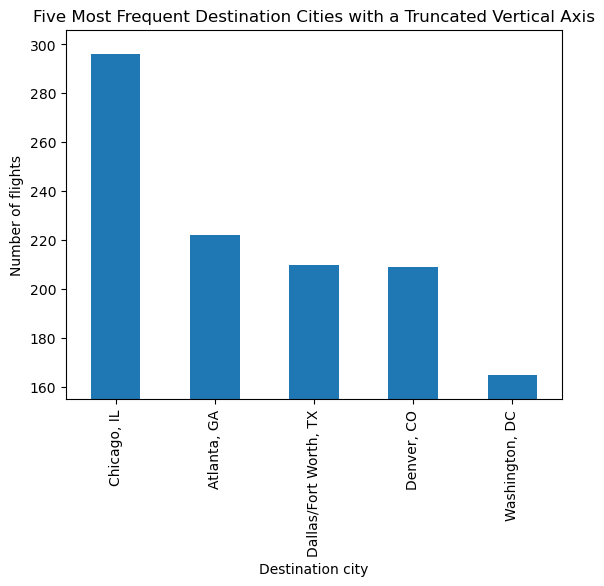

In [17]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer: The truncated vertical axis makes the differences between the destination cities look muchh larger than they actually are. Since the axis starts around 160 instead of 0, the bars appear more different in height.


**Which chart communicates the counts more honestly?**

Your answer: The first chart communicates the counts more honestly because the vertical axis starts at 0. This gives a morea ccurate visual comparison of the number of flights to each destination. 


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: May 2026


**Which flights were eligible to be included in the sample?**

Your answer: Completed, non-diverted flights, and records missing any of the five selected features were excluded.


**Which flights and records were excluded before the sample was selected?**

Your answer: Canceled flights, diverted flights, and records missing any of the five selected features were excluded.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: No. Records with missing values were removed before the sample was selected, so the original dataset could have contained missng values. 


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer: Cancled and diverted flights were excluded from teh sample, so the results only represent eligible completed flights. Those exlcuded flights may have different characteristsics. 


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: A bar chart because airlines are categorical data, and a bar chart makes it easy to compare the number of flights for each airline. 


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer: A pie chart becasue there are only three categories, and it clearly shows what propotion of the total flights belongs to each category.


**Which chart would you use to show the distribution of flight distances?**

Your answer: A histogram because flight distnace is quantitive data, and a histogram shows how the distances are distrubted acrsoss different ranges. 


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: https://www.physionet.org/content/sex-differences-hearing-loss/1.0.0/?utm_source=chatgpt.com


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [19]:
import pandas as pd

hearing_df = pd.read_csv('data/hearing_thresholds.csv', header=None)

display(hearing_df.head())
hearing_df.info()
display(hearing_df.shape)
display(hearing_df.isnull().sum())


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0,19,20,15,25,15,15,20,15,15,15,15,15,15
1,0,19,20,15,20,20,20,20,25,20,10,10,10,5
2,0,20,15,5,5,15,5,5,10,5,5,5,5,10
3,0,20,15,15,15,5,5,20,10,5,10,5,5,5
4,0,21,15,5,0,0,0,0,10,10,5,0,0,-5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4084 entries, 0 to 4083
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       4084 non-null   int64
 1   1       4084 non-null   int64
 2   2       4084 non-null   int64
 3   3       4084 non-null   int64
 4   4       4084 non-null   int64
 5   5       4084 non-null   int64
 6   6       4084 non-null   int64
 7   7       4084 non-null   int64
 8   8       4084 non-null   int64
 9   9       4084 non-null   int64
 10  10      4084 non-null   int64
 11  11      4084 non-null   int64
 12  12      4084 non-null   int64
 13  13      4084 non-null   int64
dtypes: int64(14)
memory usage: 446.8 KB


(4084, 14)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description | Data type | Storage | Missing |
|---|---|---|---|---|
| 0 | Biological sex (0=female, 1=male) | Categorical | int64 | 0 |
| 1 | Age (years) | Quantitative | int64 | 0 |
| 2 | Right ear 0.25 kHz (dB HL) | Quantitative | int64 | 0 |
| 3 | Right ear 0.5 kHz (dB HL) | Quantitative | int64 | 0 |
| 4 | Right ear 1 kHz (dB HL) | Quantitative | int64 | 0 |
| 5 | Right ear 2 kHz (dB HL) | Quantitative | int64 | 0 |
| 6 | Right ear 4 kHz (dB HL) | Quantitative | int64 | 0 |
| 7 | Right ear 8 kHz (dB HL) | Quantitative | int64 | 0 |
| 8 | Left ear 0.25 kHz (dB HL) | Quantitative | int64 | 0 |
| 9 | Left ear 0.5 kHz (dB HL) | Quantitative | int64 | 0 |
| 10 | Left ear 1 kHz (dB HL) | Quantitative | int64 | 0 |
| 11 | Left ear 2 kHz (dB HL) | Quantitative | int64 | 0 |
| 12 | Left ear 4 kHz (dB HL) | Quantitative | int64 | 0 |
| 13 | Left ear 8 kHz (dB HL) | Quantitative | int64 | 0 |

**Missing-value codes or other data preparation, if applicable:**

Your answer:   There are 4, 084 observations, 14 columns, all columns stored as int64 and no missing values in every column


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


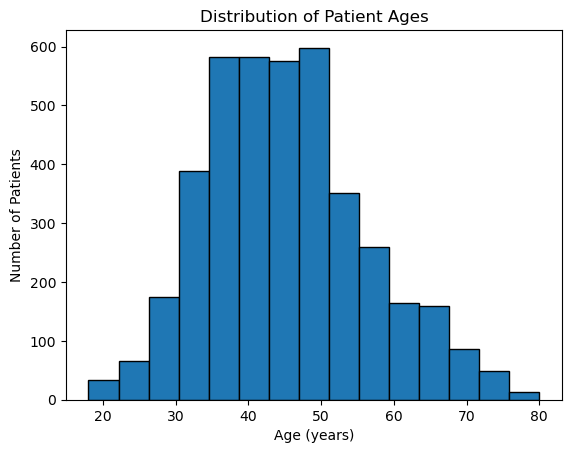

In [20]:
import matplotlib.pyplot as plt

plt.hist(hearing_df[1], bins=15, edgecolor="black")
plt.title("Distribution of Patient Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose patient age as my quantitative feature. A historgram is appropriate becasue it shows the distribution of ages and helps identify the most common age ranges in teh datasete. No missing values were excluded. 

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation: The hsitorgram shows that patient ages reange from approximately 18 to 80 years. Most patients are between 30 and 55 years old, with the highest concentration around 35 to 50 years. The distribution is slightly right-skewedd, with fewer patients in the older age groups. 


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


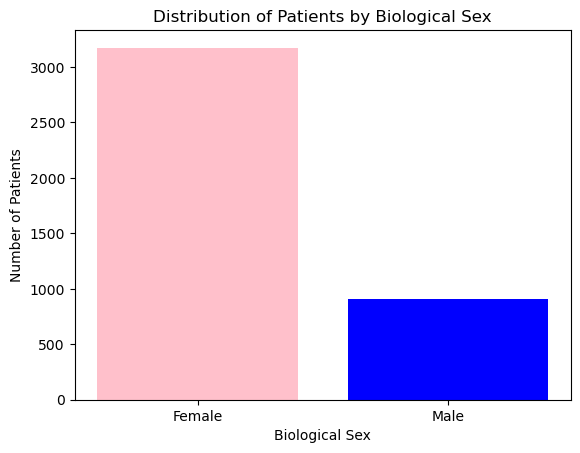

In [21]:
import matplotlib.pyplot as plt

sex_counts = hearing_df[0].value_counts().reindex([0, 1])

plt.bar(["Female", "Male"], sex_counts, color=["pink", "blue"])
plt.title("Distribution of Patients by Biological Sex")
plt.xlabel("Biological Sex")
plt.ylabel("Number of Patients")
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose biological sex as my categorical feature. A bar chart is appropriate because it compares the number of female and male patients in the dataset. No missing values were excluded. 

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation: The bar chart shwos that there are significantly more female patients than male patients in the dataset. There are 3,174 female patients and 910 male patients, meaning approximately 77.7% of the patients aere female and 22.3% are male. 


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used: Chat GPT
- What I asked it to help with: I used ChatGPT to help understand my dataser, write Python code for visualizations, and interpret my results. 
- One suggestion I checked against my code, chart, or output: I checked the histogram code by running it in jupyterlab and confirming that it displayed the patient age disribution correctly.
- What I accepted, modified, or rejected—and why: I accepted the suggested visualization code after verifying that it ran successfully and produced labeled graphs. I also checked the dataset's official data dictionary to make sure the column descriptions were accurate. 

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:


## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
